In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [4]:
df = pd.read_csv('/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv')

In [5]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

In [43]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

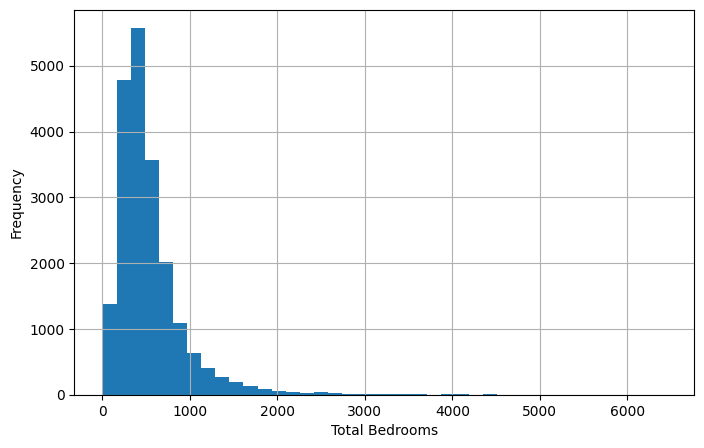

In [47]:
plt.figure(figsize=(8,5))
df["total_bedrooms"].hist(bins=40)
plt.xlabel("Total Bedrooms")
plt.ylabel("Frequency")
plt.show()

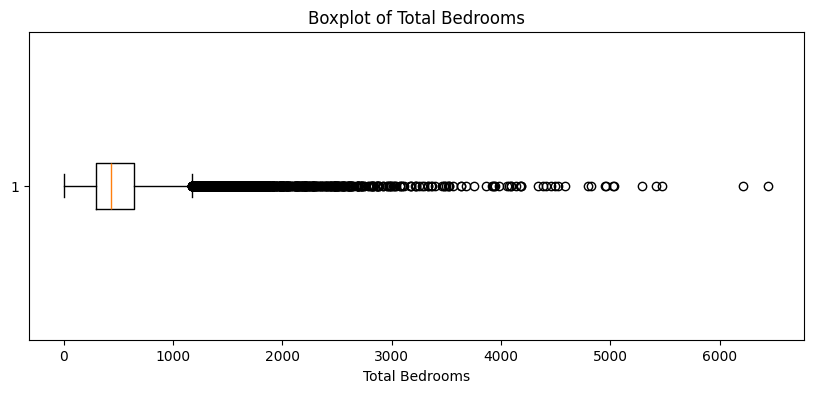

In [48]:
plt.figure(figsize=(10, 4))

plt.boxplot(df["total_bedrooms"].dropna(), vert=False)

plt.xlabel("Total Bedrooms")
plt.title("Boxplot of Total Bedrooms")

plt.show()

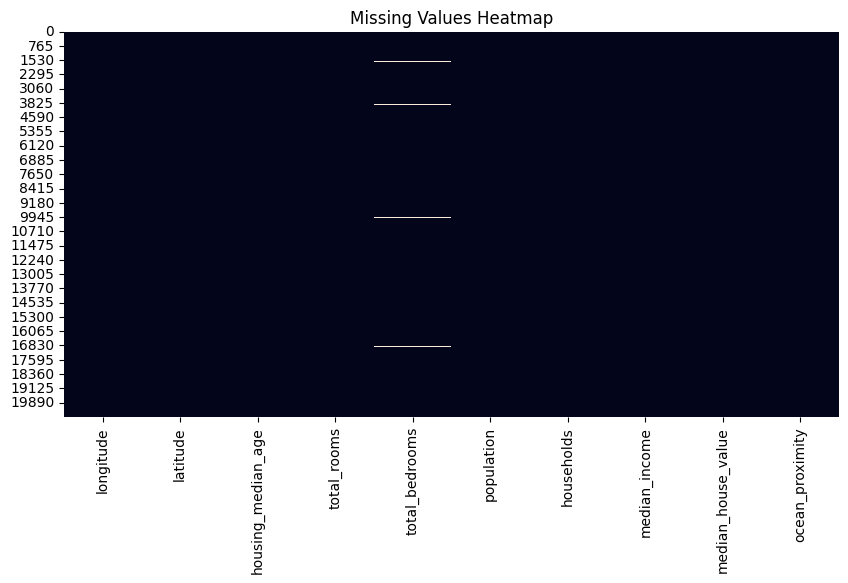

In [51]:
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [52]:
df["total_bedrooms"].mean()

np.float64(537.8705525375618)

In [53]:
df["total_bedrooms"].median()

435.0

In [54]:
df["total_bedrooms"].skew()

np.float64(3.459546331523342)

In [17]:
X = df.drop(columns= ["ocean_proximity", "median_house_value"])
y= df["median_house_value"]

In [22]:
X.shape

(20640, 8)

In [23]:
y.shape

(20640,)

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
model = LinearRegression()

In [41]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [40]:
X_train.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        169
population              0
households              0
median_income           0
dtype: int64

In [60]:
median_value = X_train["total_bedrooms"].median()
X_train["total_bedrooms"] = X_train["total_bedrooms"].fillna(median_value)

In [61]:
X_train.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
dtype: int64

In [68]:
X_test["total_bedrooms"]=X_test["total_bedrooms"].fillna(X_test["total_bedrooms"].median())

In [69]:
X_test.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
dtype: int64

In [66]:
model.fit(X_train, y_train)

LinearRegression()

In [70]:
model.predict(X_test)

array([102123.43556642, 205980.41780686, 340988.09034913, ...,
       220088.0317454 , -42030.70300202, 226276.78603066])

In [71]:
y_test

13882     99300.0
3190     107500.0
8299     500000.0
1120      97300.0
9776     164600.0
           ...   
1410     220800.0
5671     326700.0
16867    265100.0
3369      60700.0
9684     159900.0
Name: median_house_value, Length: 4128, dtype: float64

In [72]:
model.coef_

array([-4.27629211e+04, -4.25667424e+04,  1.14805984e+03, -6.14620205e+00,
        8.04206407e+01, -4.07715236e+01,  7.86572487e+01,  3.96419749e+04])

In [75]:
model.intercept_

np.float64(-3583947.583831725)

In [80]:
mae = mean_absolute_error(y_test, model.predict(X_test) )
print("MAE:", mae)

MAE: 50767.34358011434


In [81]:
mse = mean_squared_error(y_test, model.predict(X_test) )
print("MSE:", mse)

MSE: 4842984616.155041


In [85]:
rmse = np.sqrt(mse)
r2 = r2_score(y_test, model.predict(X_test))
print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 69591.5556382744
R2 Score: 0.6444307259253039


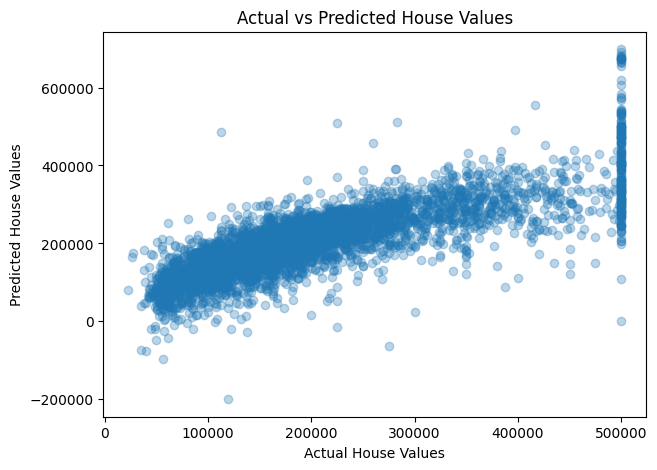

In [87]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, model.predict(X_test), alpha=0.3)
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")
plt.show()